In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import f_classif
from sklearn.preprocessing import StandardScaler

# #1

### a)

Text(0.5, 1.0, 'Frequency of Each Food Group')

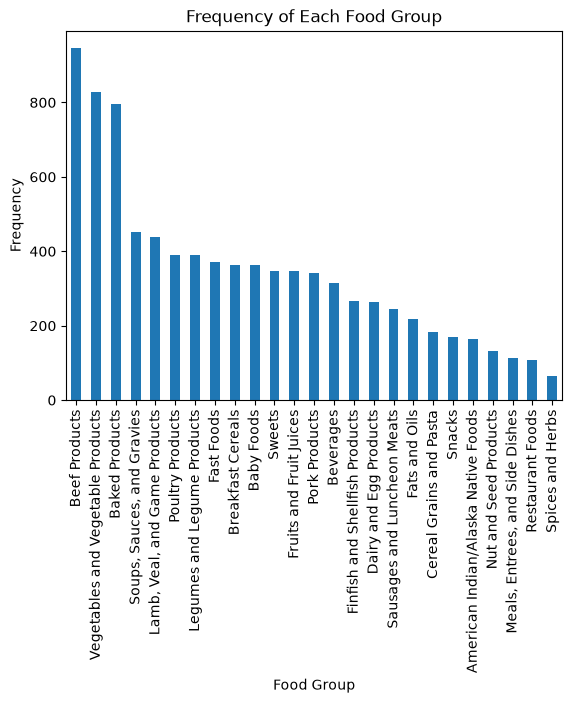

In [2]:
nndb = pd.read_csv("nndb_flat.csv")

# Using a bar chart to determine frequencies of the different food groups
nndb["FoodGroup"].value_counts().plot(kind='bar')
plt.xlabel("Food Group")
plt.ylabel("Frequency")
plt.title("Frequency of Each Food Group")

This data not very well balanced because there is a large variation between the frequncy of the different food groups. Some of these categories like beef, vegetable, and baked products have around 800 occurences while others like restaurant foods and spices have around 100 occurences making a large range of occurences.

### b)

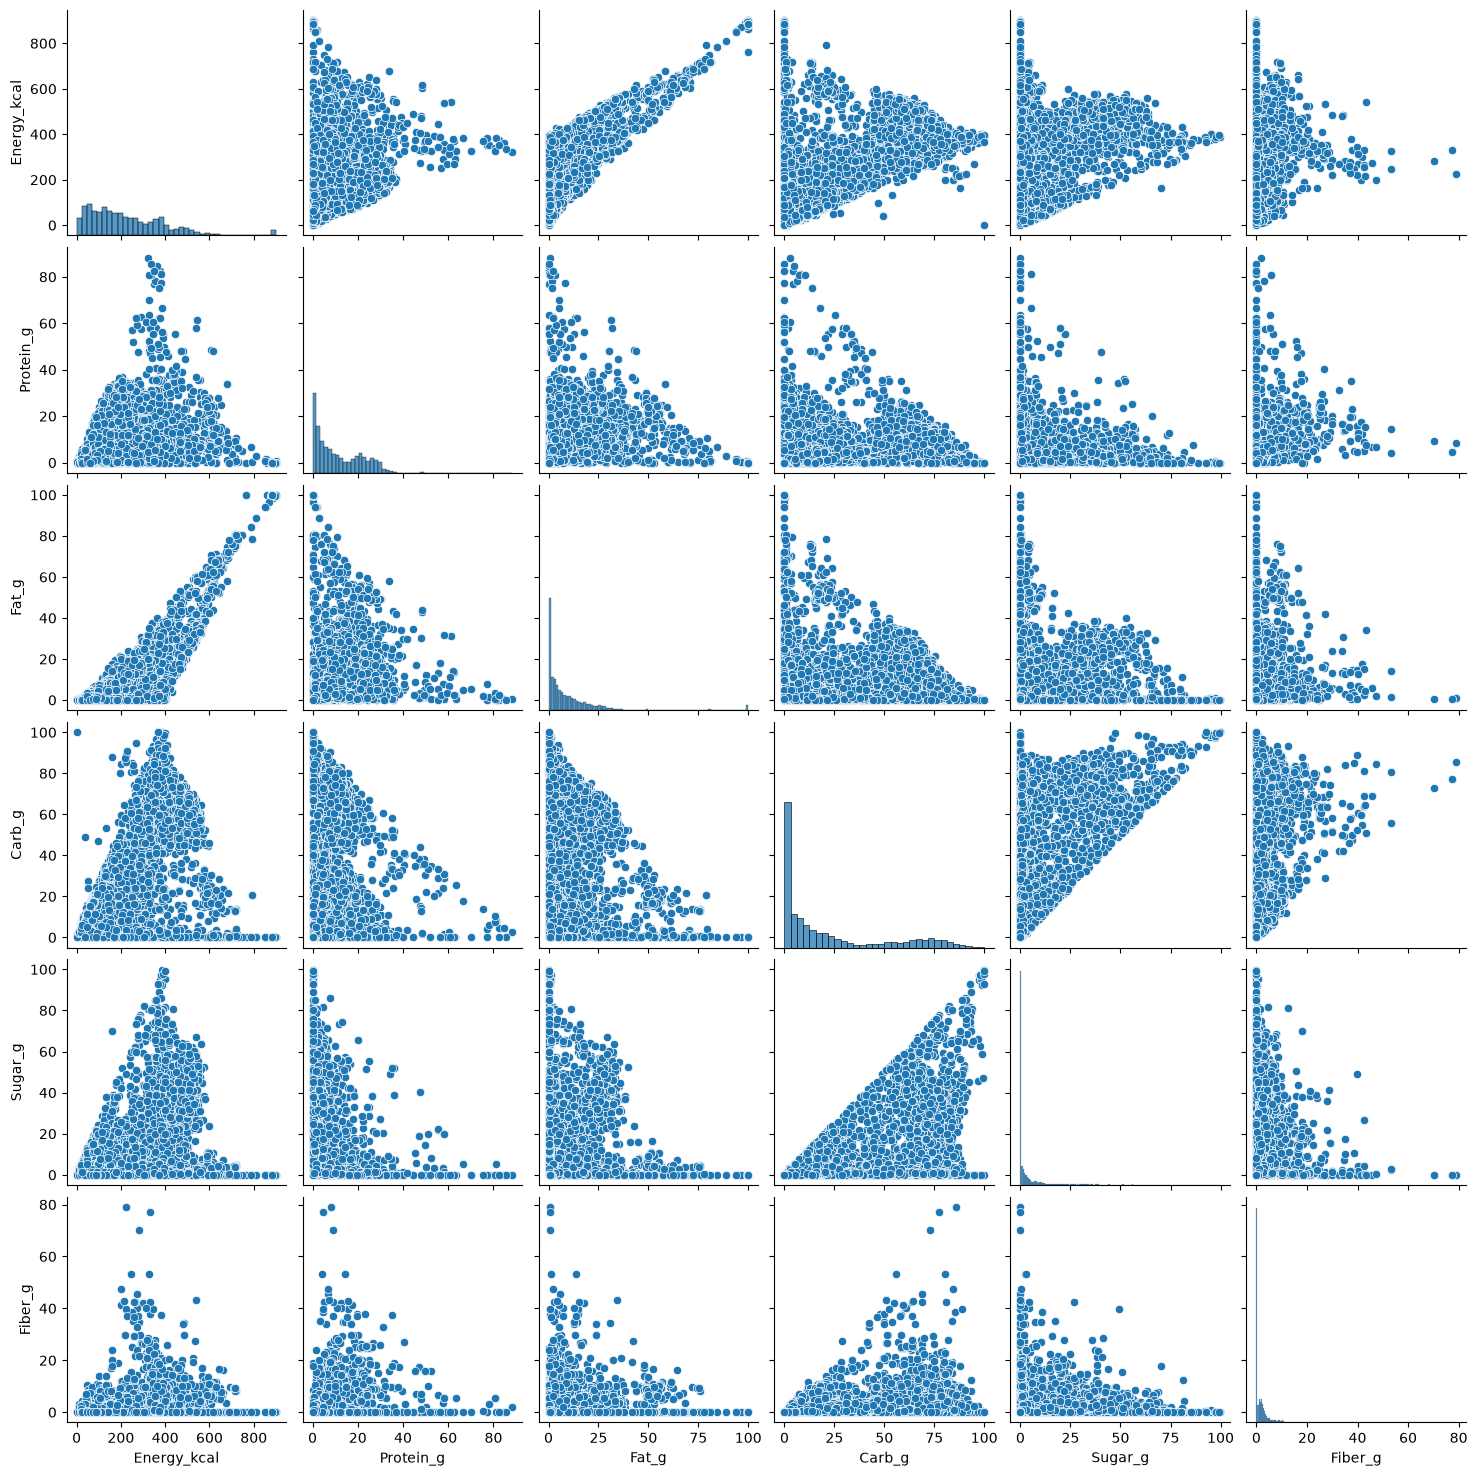

In [9]:
# Creating pairplots of the numerical data, using only the first 6 numerical instances due to the large number of numerical variables
# Using all the numerical variables makes the plots unusable
short_nndb = nndb.iloc[:,7:13]
sns.pairplot(short_nndb)

<Axes: >

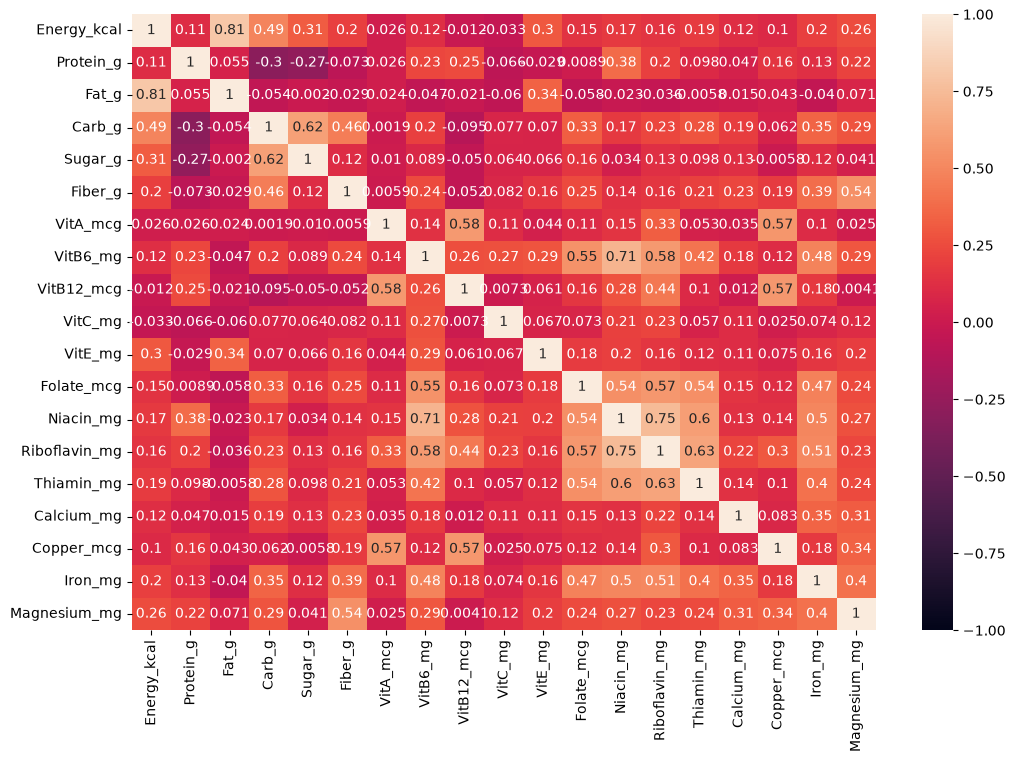

In [18]:
# Creating a heatmap of the numerical values, excluding the scaled values
short_nndb = nndb.iloc[:,7:26]
corr_matrix = short_nndb.select_dtypes(include='number').corr()
fig, ax = plt.subplots(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, vmin=-1, vmax=1, ax=ax)

The pairplots don't work quite as well for these xs as the heatmap does, this is due to the large number of possible x variables. By having a correlation heatmap, it becomes easier to see the relationships between the different x variables due to the condensed display of the information. 

### c)

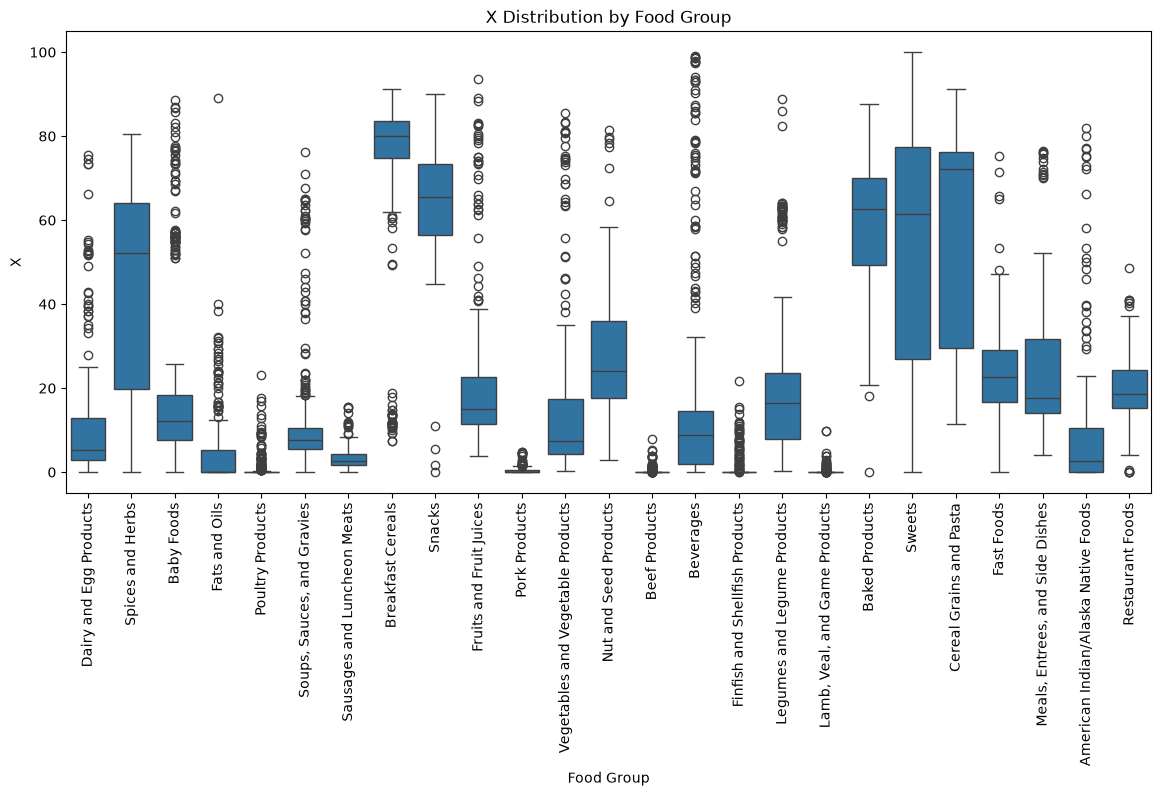

In [24]:
# Test out different possible numeric predictors using box plots of all the different possible food groups to see if there are
# Noticable differences in the box plots
plt.figure(figsize=(14, 6))
sns.boxplot(data=nndb, x="FoodGroup", y="Carb_g")

plt.title("X Distribution by Food Group")
plt.xlabel("Food Group")
plt.ylabel("X")
plt.xticks(rotation=90)
plt.show()

In [23]:
# Use an ANOVA evaluation to see which predictors have the largest difference in the means of the different food groups
X = nndb.select_dtypes(include="number").drop(columns=["FoodGroup"], errors="ignore")
y = nndb["FoodGroup"]

f_stats, p_values = f_classif(X, y)

results = pd.DataFrame({"Predictor": X.columns, "F-statistic": f_stats, "p-value": p_values})
results = results.sort_values("F-statistic", ascending=False)

print(results)

           Predictor  F-statistic        p-value
4             Carb_g   875.940928   0.000000e+00
2          Protein_g   582.609545   0.000000e+00
1        Energy_kcal   409.409758   0.000000e+00
0                 ID   391.921888   0.000000e+00
3              Fat_g   368.038733   0.000000e+00
5            Sugar_g   216.544594   0.000000e+00
18           Iron_mg   195.408347   0.000000e+00
6            Fiber_g   191.289948   0.000000e+00
35   Magnesium_USRDA   159.004501   0.000000e+00
19      Magnesium_mg   159.004501   0.000000e+00
13         Niacin_mg   151.378941   0.000000e+00
30      Niacin_USRDA   151.378941   0.000000e+00
25       VitB6_USRDA   147.320704   0.000000e+00
8           VitB6_mg   147.320704   0.000000e+00
38        Zinc_USRDA   140.782146   0.000000e+00
23           Zinc_mg   140.782146   0.000000e+00
29      Folate_USRDA   129.373719   0.000000e+00
12        Folate_mcg   129.373719   0.000000e+00
32     Thiamin_USRDA    75.715291   0.000000e+00
15        Thiamin_mg

Candidate Xs: Carb_g, Protein_g, Energy_kcal, Fat_g, Sugar_g, Iron_mg, and Fiber_g from this evaluation

### d)

In [26]:
# Using the heatmap these were found to be some of the most closely correlated predictors in the data
# Combining these may help to alleviate potiential multicollinearity
scaler = StandardScaler()

nndb[["VitB6_USRDA_scaled", "Niacin_USRDA_scaled"]] = scaler.fit_transform(nndb[["VitB6_USRDA", "Niacin_USRDA"]])
nndb["VitB6_Niacin_combined"] = (nndb["VitB6_USRDA_scaled"] + nndb["Niacin_USRDA_scaled"]) / 2

nndb[["Energy_kcal_scaled", "Fat_g_scaled"]] = scaler.fit_transform(nndb[["Energy_kcal", "Fat_g"]])
nndb["Energy_Fat_combined"] = (nndb["Energy_kcal_scaled"] + nndb["Fat_g_scaled"]) / 2

nndb[["Carb_g_scaled", "Sugar_g_scaled"]] = scaler.fit_transform(nndb[["Carb_g", "Sugar_g"]])
nndb["Carb_Sugar_combined"] = (nndb["Carb_g_scaled"] + nndb["Sugar_g_scaled"]) / 2

# #2

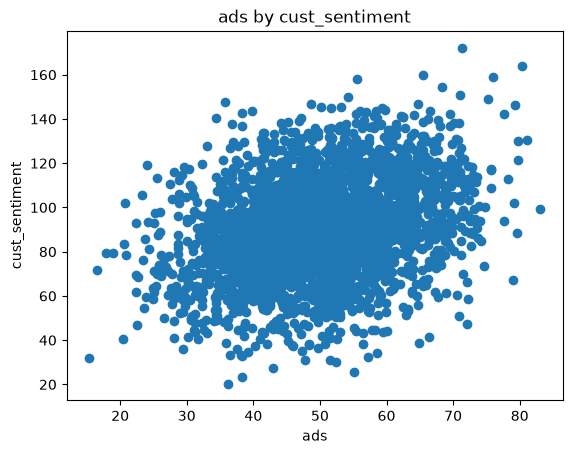

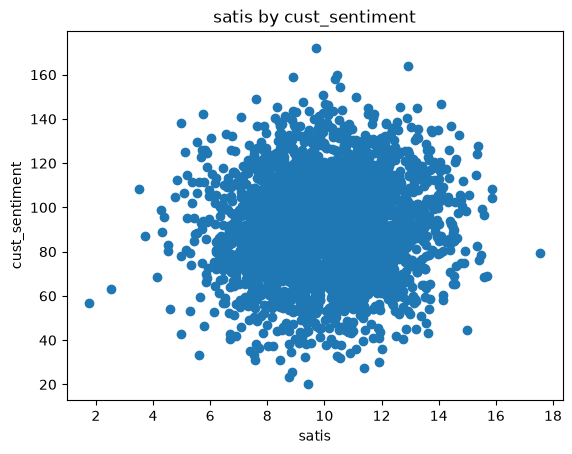

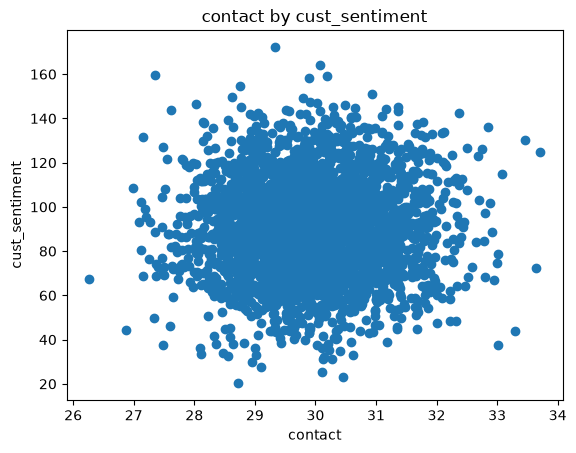

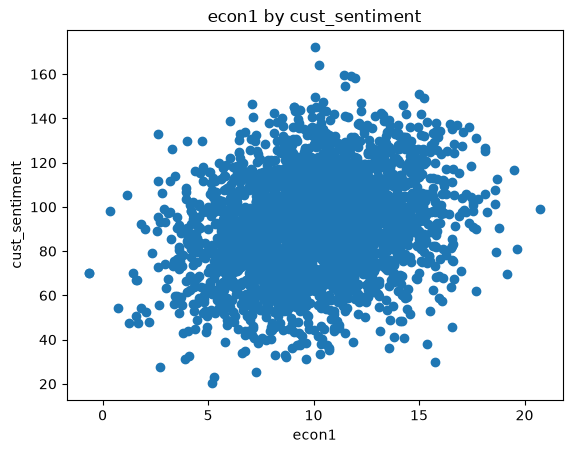

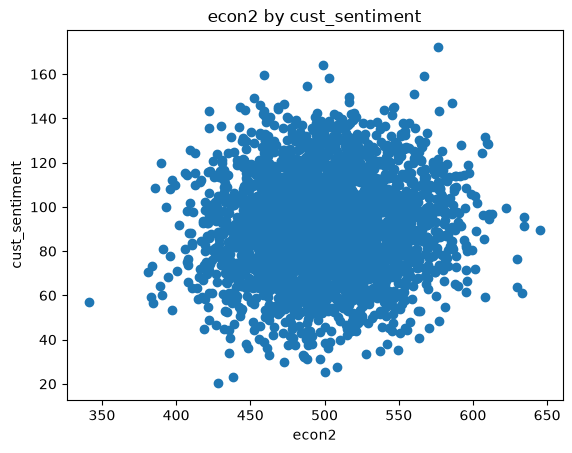

In [32]:
def generic_eda(data):
    X = data.iloc[:,1:]
    y = data.iloc[:,0]

    for i in X.columns:
        plt.scatter(X[i], y)
        plt.title(f"{i} by {y.name}")
        plt.xlabel(f"{i}")
        plt.ylabel(f"{y.name}")
        plt.show()
        
reg1 = pd.read_csv("reg1.csv")
generic_eda(reg1)

# #3

### a)

ChatGPT: 
1. Start in Your Backyard or a Local Park
2. Get a Pair of Binoculars
3. Download a Bird Identification App
4. Learn to Recognize Five Common Birds
5. Keep a Simple Birdwatching Journal

Claude:
1. Get basic gear
2. Start close to home
3. Go at the right time
4. Learn to observe, not just look
5. Keep a list and connect with others

### b)

ChatGPT:
1. Find a Good Spot
2. Get Some Binoculars
3. Download a Bird Identification App
4. Learn Five Common Birds
5. Keep a Birdwatching Journal

Claude:
1. Pick up binoculars and a field guide or app.
2. Choose a spot nearby.
3. Go early.
4. Focus on key features.
5. Log what you see.

### c)

https://www.nps.gov/articles/birding-for-beginners.htm

Suggestions from the National Parks Service:
1. Choose the correct bird guide for you (complexity, region, format, etc.)
2. Binoculars and spotting scopes
3. Positive attitude and patience
4. Get to know your regulars
5. Find a good spot
6. Choose the right time of day and season
7. Blend in
8. Practice with your binoculars
9. Take notes

### d)

For the accuracy of the information, both ChatGPT and Claude seem to align with many of the points mentioned by the National Parks Service in their guide to beginners bird watching. Some of the information recieved from the AI agents was more specific than what the National Parks Service suggested. For example ChatGPT suggests downloading a bird identification app and learning five common birds whereas the National Parks Service keeps it more broad, suggesting finding the correct bird guide for you and the getting to know your regulars. The same applies for Claude, Claude suggests going early, whereas the National Parks Service suggests finding the right time to watch birds for your area. For the consistency of the responses, ChatGPT gave nearly identical responses for both the prompts. There was some minor rewording but ChatGPT suggests the same five steps in both responses. For Claude, the same general five points were kept, however the second response was clearly intentionally different from the first response as Claude avoided recommending the exact same steps, while still trying to convey the same general steps. This means that ChatGPT seemed to have more consistent responses between the two AI models.

# #5

In [39]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split

heart = pd.read_csv("Heart.csv")
heart["AHD"] = heart["AHD"].map({"Yes": 1, "No": 0})
X_train, X_test, y_train, y_test = train_test_split(heart[["Age", "Sex", "RestBP", "Chol", "Fbs", "RestECG", "MaxHR", "ExAng", "Oldpeak", "Slope"]], heart["AHD"], test_size=0.2, random_state=99)

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Original Model:")
print(classification_report(y_test, y_pred))

weighted_model = LogisticRegression(class_weight={0: 1, 1: 2}, max_iter=1000)
weighted_model.fit(X_train, y_train)
y_pred_weighted = weighted_model.predict(X_test)

print("Weighted Model:")
print(classification_report(y_test, y_pred_weighted))

Original Model:
              precision    recall  f1-score   support

           0       0.70      0.81      0.75        32
           1       0.75      0.62      0.68        29

    accuracy                           0.72        61
   macro avg       0.73      0.72      0.72        61
weighted avg       0.73      0.72      0.72        61

Weighted Model:
              precision    recall  f1-score   support

           0       0.81      0.69      0.75        32
           1       0.71      0.83      0.76        29

    accuracy                           0.75        61
   macro avg       0.76      0.76      0.75        61
weighted avg       0.76      0.75      0.75        61



For a model like this, where we are looking to evaluate heart disease we want to err on the side of caution. This means we want to ensure we catch as many positive cases as possible. This means we want to try to maximize the recall of our model as this evaluates how many of the true positives we correctly predicted. To achieve this, we can weight the positive response to the AHD variable so that the model values a correct positive response more than a correct negative response. Looking at the recall variable for both the original model and the weighted model it becomes apparant that the weighting of the positive variable does help to increase the recall of the weighted model. The original model has a recall of .62 for the positive variable and the weighted model improves this recall to .83 for the positive response.